In [1]:
import pandas as pd 
import numpy as np

In [3]:
data = pd.read_csv('3d_metal_data.csv')

# Keep only the specified columns
columns_to_keep = ['Formula', 'M_s', 'T_C', 'Pugh', 'Cauchy']
# df = data[columns_to_keep].tail(401)
df = data[columns_to_keep]
columns_to_normalize_old = ['M_s', 'T_C', 'Pugh', 'Cauchy']
columns_to_normalize = [f"{i}_new" for i in columns_to_normalize_old]
df[columns_to_normalize] = df[columns_to_normalize_old].copy().apply(
    lambda x: (x - x.min()) / (x.max() - x.min())
)
df['pareto'] = np.sqrt(df['M_s_new']**2 + df['T_C_new']**2 + df['Pugh_new']**2 + df['Cauchy_new']**2)
df.describe()

/home/md88vyxi/.local/lib/python3.6/site-packages/pandas/core/frame.py:3069: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self[k1] = value[k2]
/home/md88vyxi/.local/lib/python3.6/site-packages/ipykernel_launcher.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  if sys.path[0] == '':


,M_s,T_C,Pugh,Cauchy,M_s_new,T_C_new,Pugh_new,Cauchy_new,pareto
count,472.000000,472.000000,472.000000,472.000000,472.000000,472.000000,472.000000,472.000000,472.000000
mean,0.175132,296.363643,2.490623,24.137836,0.249384,0.192422,0.325224,0.579987,0.796007
std,0.170995,325.349667,0.363424,15.794194,0.243494,0.211242,0.074104,0.105752,0.167744
min,0.000000,0.000000,0.895650,-62.483518,0.000000,0.000000,0.000000,0.000000,0.110010
25%,0.000859,0.062141,2.295952,15.148457,0.001224,0.000040,0.285530,0.519797,0.703062
50%,0.149307,177.170037,2.508167,25.354799,0.212611,0.115032,0.328801,0.588135,0.785023
75%,0.286727,512.506954,2.697268,32.555362,0.408294,0.332759,0.367360,0.636347,0.870717
max,0.702256,1540.174280,5.799876,86.867106,1.000000,1.000000,1.000000,1.000000,1.490060


In [4]:
sorted_df = df.sort_values(by=['pareto'],ascending=False).reset_index(drop=True)
df_unique = sorted_df.drop_duplicates(subset=['Formula'], keep='first')
df_unique.to_csv('sorted_df.csv', index=False)
# sorted_df['Formula']

In [5]:
# Calculate average and standard deviation for every 10 rows
step = 10
grouped_stats = df[['M_s_new', 'T_C_new', 'Pugh_new', 'Cauchy_new', 'pareto']].groupby(df.index // step).agg(['mean', 'std'])

# Extract the means and standard deviations
means = grouped_stats.xs('mean', level=1, axis=1)
stds = grouped_stats.xs('std', level=1, axis=1)

In [16]:
# !pip3 install seaborn --user

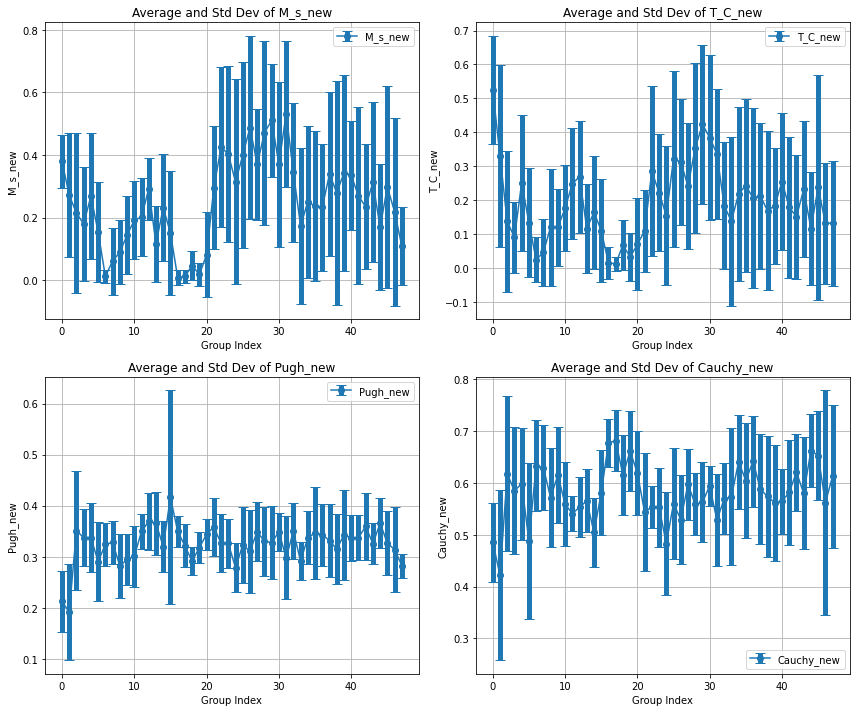

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
# Create a 2x2 subplot for the data
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Column names for iteration
columns = means.columns
# titles = ['M_s', 'T_C', 'Pugh', 'Cauchy']
titles = columns_to_normalize

# Plot each column in the appropriate subplot
for idx, ax in enumerate(axs.flatten()):
    column = columns[idx]
    ax.errorbar(means.index, means[column], yerr=stds[column], fmt='o-', capsize=5, label=column, elinewidth=5)
    # ax.fill_between(means.index, means[column] - stds[column], means[column] + stds[column], color='gray', alpha=0.3, label='Error Band')
    # sns.pointplot(data=df, x='Group', y='Value', capsize=0.2, errwidth=1, ci='sd', color='b')
    ax.set_title(f"Average and Std Dev of {titles[idx]}")
    ax.set_xlabel("Group Index")
    ax.set_ylabel(titles[idx])
    ax.grid()
    ax.legend()

# Adjust layout
plt.tight_layout()
plt.show()

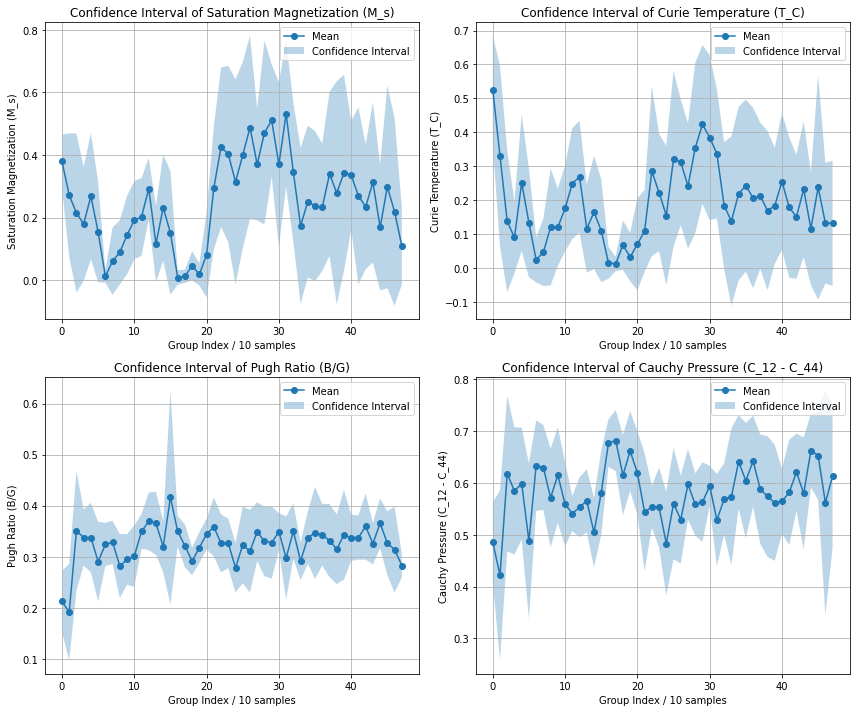

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
# Create a 2x2 subplot for the data
fig, axs = plt.subplots(2, 2, figsize=(12, 10))
titles = ['Saturation Magnetization (M_s)', 'Curie Temperature (T_C)', 'Pugh Ratio (B/G)', 'Cauchy Pressure (C_12 - C_44)']

# Column names for iteration
columns = means.columns
# titles = ['M_s', 'T_C', 'Pugh', 'Cauchy']
# titles = columns_to_normalize

# Plot each column in the appropriate subplot
for idx, ax in enumerate(axs.flatten()):
    column = columns[idx]
    ax.plot(means.index, means[column], marker='o', label='Mean')
    ax.fill_between(
        means.index,
        means[column] - stds[column],
        means[column] + stds[column],
        alpha=0.3,
        label='Confidence Interval'
    )
    ax.set_title(f'Confidence Interval of {titles[idx]}')
    ax.set_xlabel('Group Index / 10 samples')
    ax.set_ylabel(titles[idx])
    ax.grid()
    ax.legend()

# Adjust layout
plt.tight_layout()
plt.show()

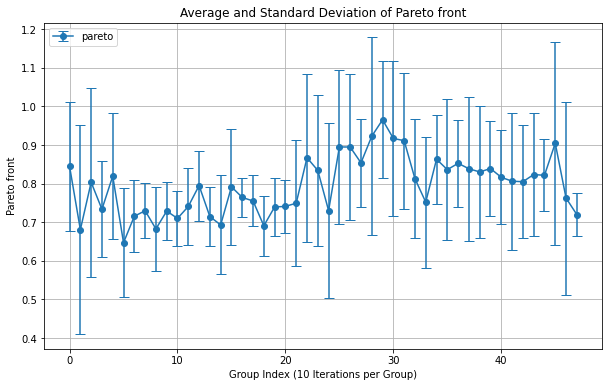

In [8]:
plt.figure(figsize=(10, 6))
plt.errorbar(means.index, means['pareto'], yerr=stds['pareto'], fmt='o-', capsize=5, label='pareto')
plt.title("Average and Standard Deviation of Pareto front")
plt.xlabel("Group Index (10 Iterations per Group)")
plt.ylabel('Pareto front')
plt.legend()
plt.grid()
plt.show()

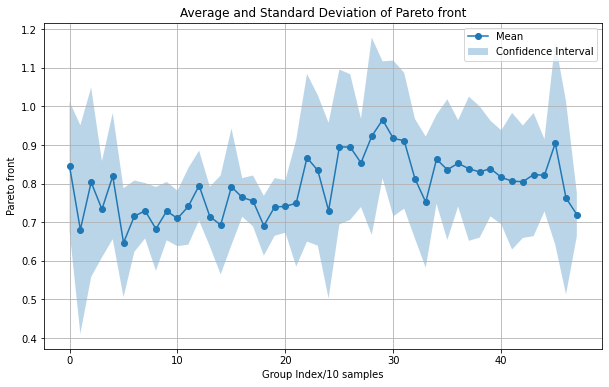

In [9]:
plt.figure(figsize=(10, 6))
# plt.errorbar(means.index, means['pareto'], yerr=stds['pareto'], fmt='o-', capsize=5, label='pareto')
plt.plot(means.index, means['pareto'], marker='o', label='Mean')
plt.fill_between(
    means.index,
    means['pareto'] - stds['pareto'],
    means['pareto'] + stds['pareto'],
    alpha=0.3,
    label='Confidence Interval'
)
plt.title("Average and Standard Deviation of Pareto front")
plt.xlabel("Group Index/10 samples")
plt.ylabel('Pareto front')
plt.legend()
plt.grid()
plt.show()
# ax.plot(means.index, means[column], marker='o', label='Mean')
# ax.fill_between(
#     means.index,
#     means[column] - stds[column],
#     means[column] + stds[column],
#     alpha=0.3,
#     label='Confidence Interval'
# )

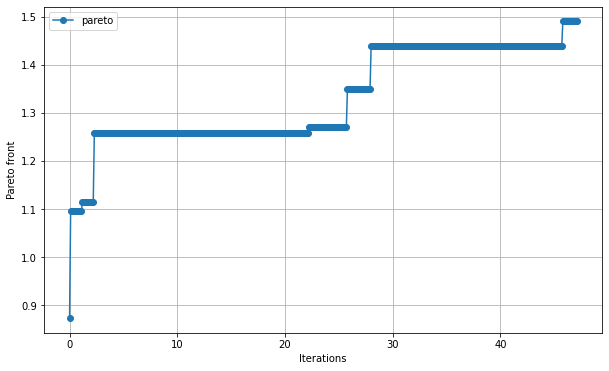

In [10]:
df['max_pareto'] = df['pareto'].expanding().max()
plt.figure(figsize=(10, 6))
plt.errorbar(df.index/10, df['max_pareto'], fmt='o-', capsize=1, label='pareto')
# plt.title("Average and Standard Deviation of Pareto front")
plt.xlabel("Iterations")
plt.ylabel('Pareto front')
plt.legend()
plt.grid()
plt.show()

                                Formula       M_s          T_C      Pugh  \
0   Fe0.359Co0.362Ni0.097Cu0.094Zn0.088  0.595603  1540.174280  2.465197   
1   Mn0.107Fe0.324Co0.377Ni0.146Zn0.046  0.702256  1294.327846  2.141751   
2   Mn0.102Fe0.261Co0.363Ni0.201Zn0.073  0.634686  1108.332322  2.452568   
3   Mn0.039Fe0.427Co0.074Ni0.067Cu0.393  0.507336  1149.907290  2.781018   
4   Cr0.055Fe0.262Ni0.184Cu0.242Zn0.257  0.218474   469.086455  3.973863   
5   Mn0.102Fe0.369Co0.152Ni0.328Zn0.049  0.639750   833.651846  2.410717   
6   Sc0.113Mn0.154Fe0.376Co0.191Ni0.166  0.612091  1036.176689  2.013650   
7   Mn0.131Fe0.247Co0.273Ni0.269Zn0.080  0.603627   861.678742  2.447926   
8   Fe0.202Co0.352Ni0.279Cu0.109Zn0.058  0.475759   906.756549  2.581045   
9   Mn0.226Fe0.189Co0.335Ni0.164Zn0.086  0.635357   808.887592  1.940103   
10  Sc0.243Mn0.115Fe0.332Co0.231Zn0.079  0.443309  1193.121188  2.008288   
11   Sc0.191Ti0.172V0.171Cr0.233Zn0.233  0.000000     0.000000  5.799876   
12  Mn0.096F

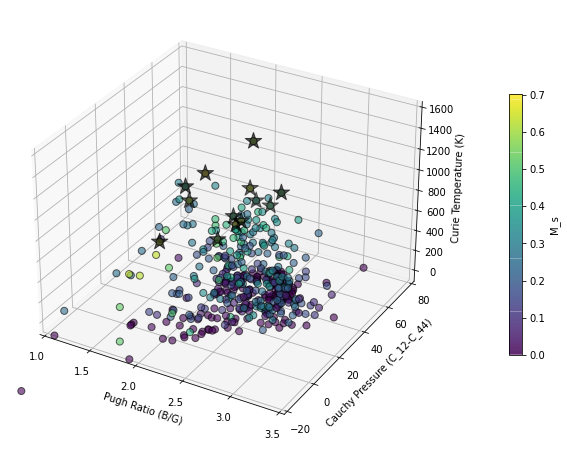

In [23]:
data = pd.read_csv('sorted_df.csv')
top_10 = data.head(15)
print(top_10)
from mpl_toolkits.mplot3d import Axes3D

# Extract data for plotting
x = data['Pugh']
y = data['Cauchy']
z = data['T_C']
c = data['M_s']

# Create 3D scatter plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot with color representing 'M_s'
sc = ax.scatter(x, y, z, c=c, cmap='viridis', s=50, alpha=0.6, edgecolor='k')

# Add color bar for M_s
cb = fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.1)
cb.set_label('M_s')

ax.scatter(top_10['Pugh'], top_10['Cauchy'], top_10['T_C'], 
           c='black', marker='*', s=300, label='Pareto front')

# Set axis labels
ax.set_xlabel('Pugh Ratio (B/G)')
ax.set_ylabel('Cauchy Pressure (C_12-C_44)')
ax.set_zlabel('Curie Temperature (K)')

ax.set_xlim([1, 3.5])  # Adjust the range of the x-axis (Pugh Ratio)
ax.set_ylim([-20, 80])  # Adjust the range of the y-axis (Cauchy Pressure)
# ax.set_zlim([0, 1400])  # Adjust the range of the z-axis (T_C)

# Display the plot
# plt.title('3D Scatter Plot of Materials Properties')
plt.show()

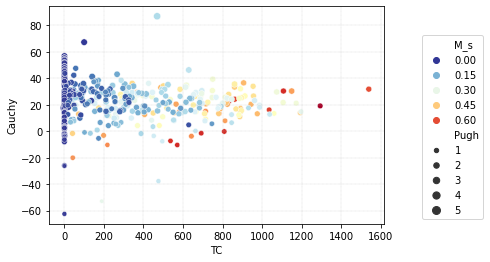

In [25]:
data = pd.read_csv('sorted_df.csv')
fig, ax = plt.subplots()

ax = sns.scatterplot(data=data, 
                     x="T_C", 
                     y="Cauchy", 
                     hue = "M_s",
                     size = "Pugh",
                     palette = 'RdYlBu_r')

# size 用散点大小表达花瓣宽度

ax.set_xlabel('TC')
ax.set_ylabel('Cauchy')
# ax.set_xticks(np.arange(4, 8 + 1, step=1))
# ax.set_yticks(np.arange(1, 5 + 1, step=1))
# ax.axis('scaled')
ax.grid(linestyle='--', linewidth=0.25, color=[0.7,0.7,0.7])
# ax.set_xbound(lower = 4, upper = 8)
# ax.set_ybound(lower = 1, upper = 5)
ax.legend(loc='lower left', bbox_to_anchor=(1.1, 0), ncol=1)
# 将图例置于散点图之外，放置方式为左下
# 图例定位点为 (1.1, 0)
# 其他放置方式：'best', 'upper right', 'upper left', 'lower left', 
# 'lower right', 'right', 'center left', 'center right', 
# 'lower center', 'upper center', 'center'

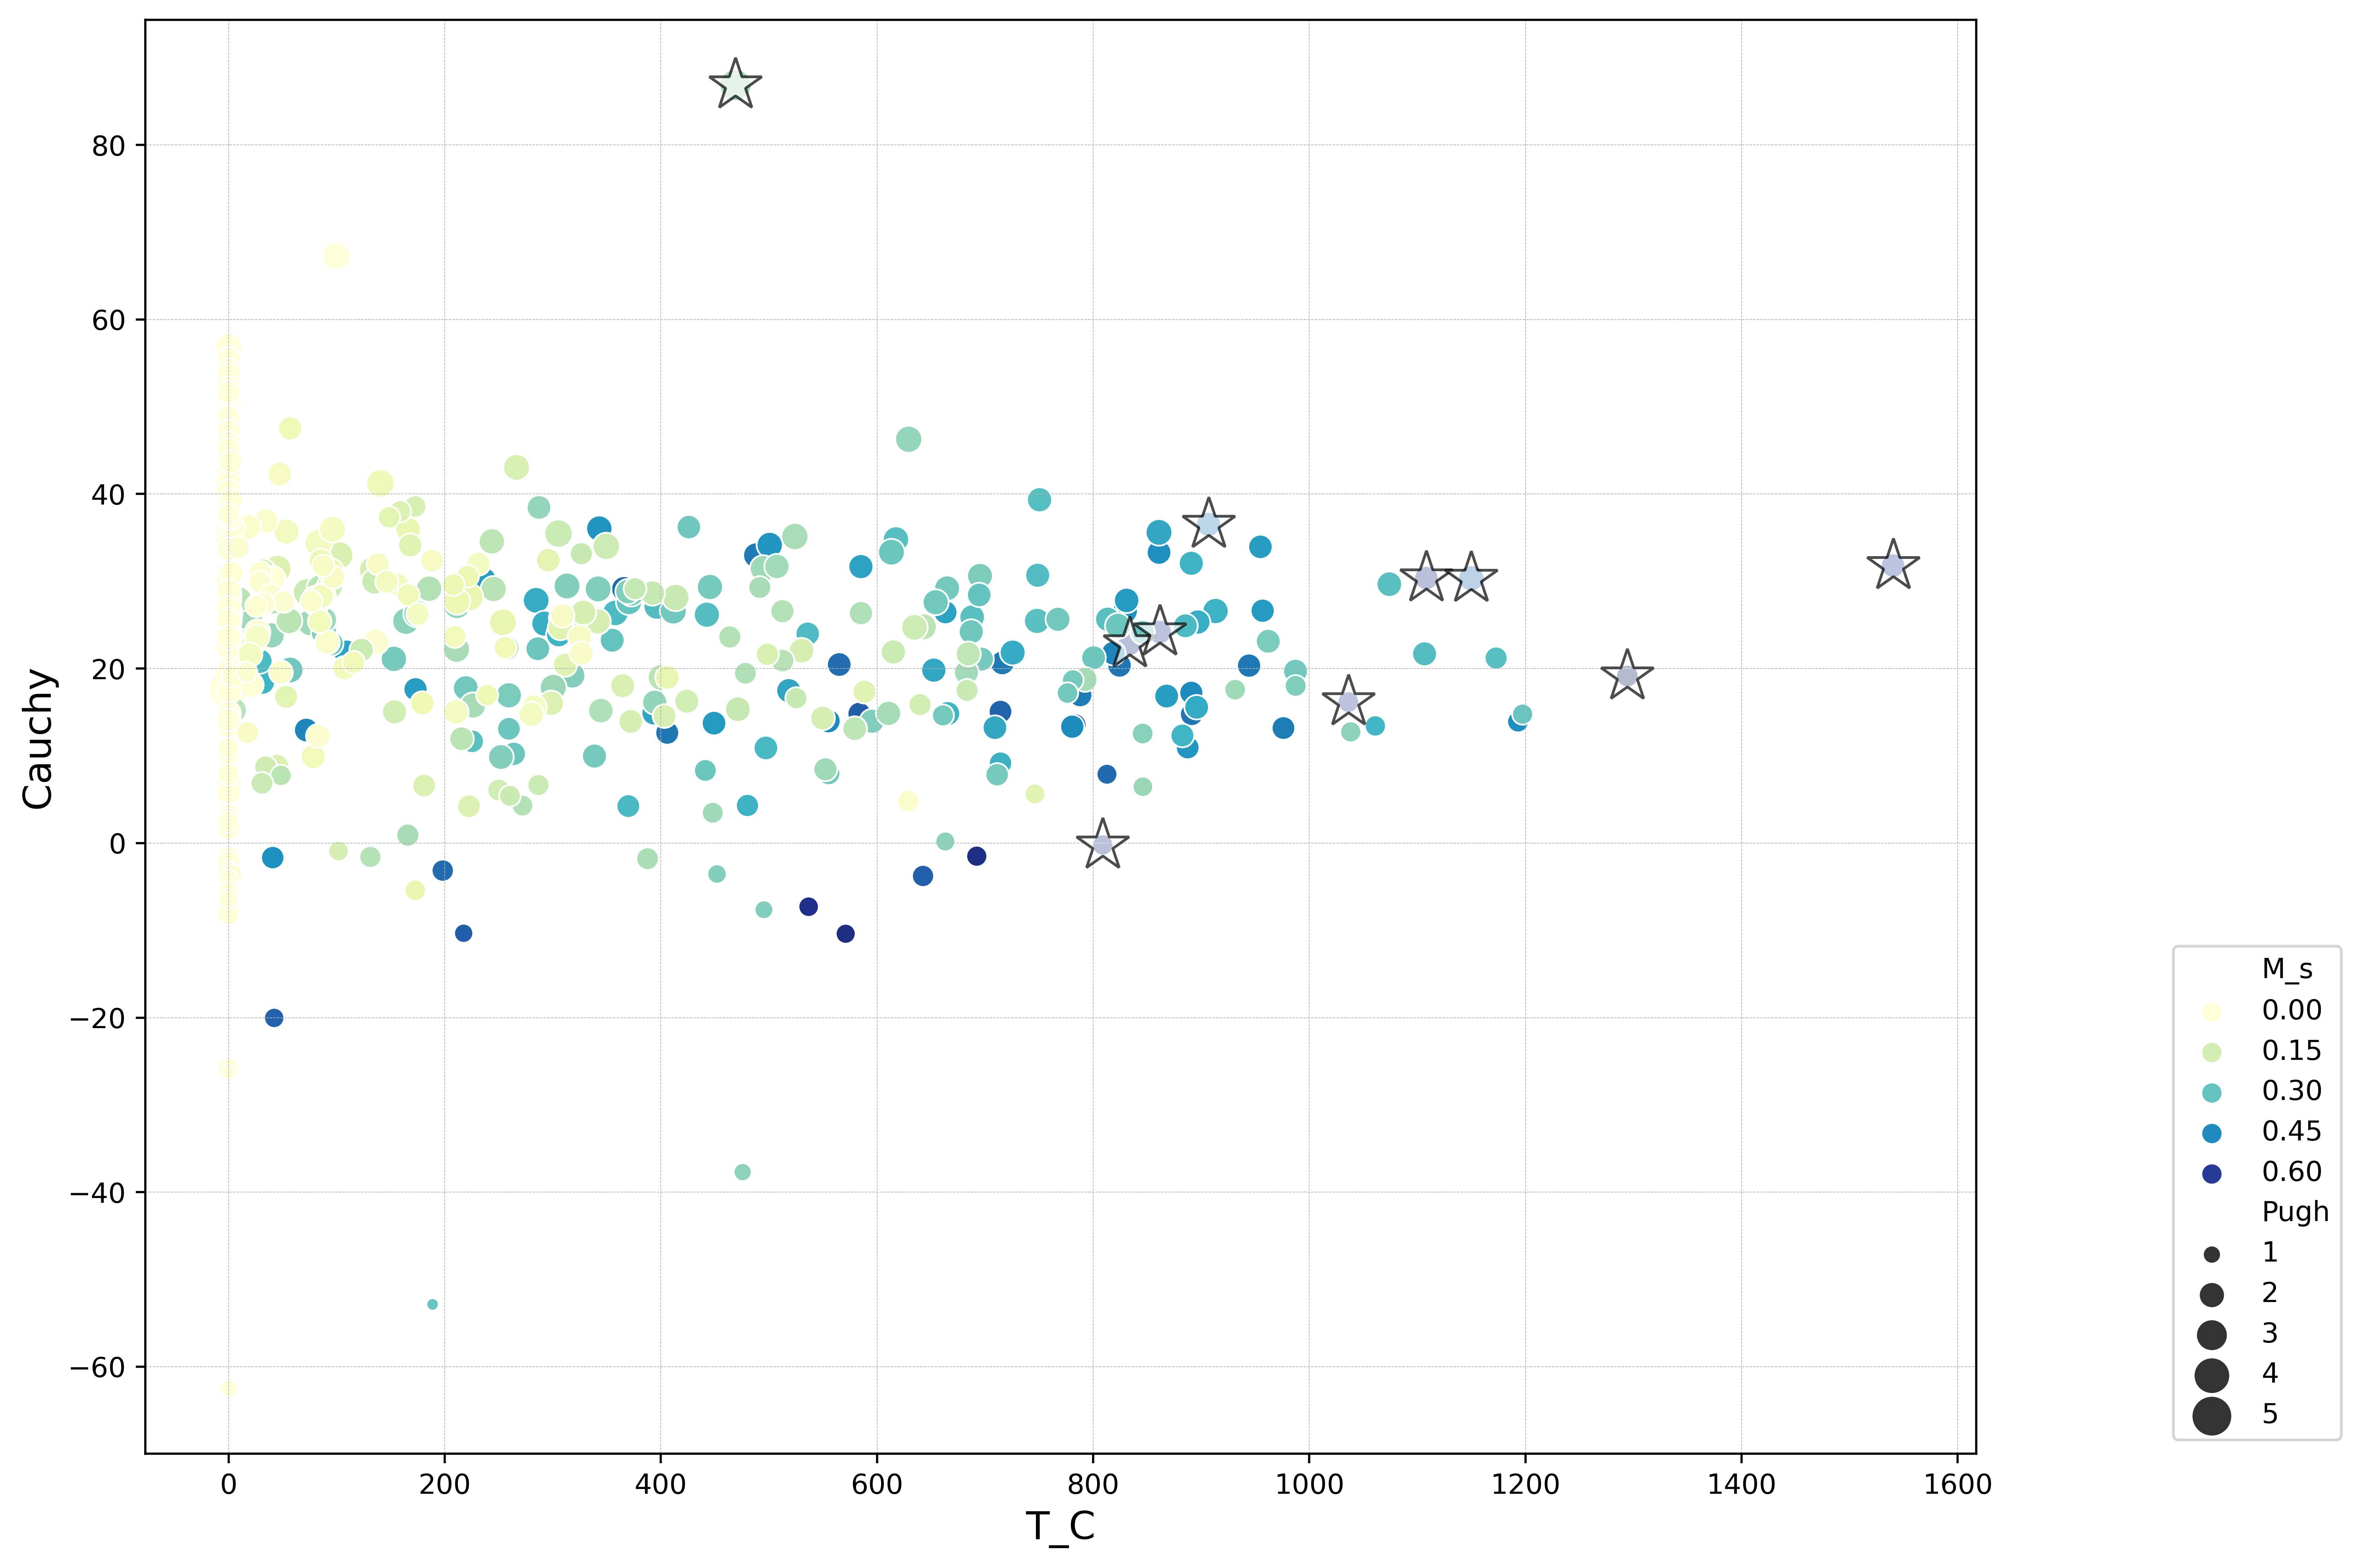

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 读取数据
data = pd.read_csv('sorted_df.csv')
pareto_points = data.head(10)
# 设置图片大小和分辨率
plt.figure(figsize=(12, 8), dpi=500)

# 绘制散点图
ax = sns.scatterplot(
    data=data, 
    x="T_C", 
    y="Cauchy", 
    hue="M_s", 
    size="Pugh", 
    # palette='RdYlBu_r',
    palette = 'YlGnBu',
    sizes=(20, 200)
    # hue_norm=(data['M_s'].min() - (data['M_s'].max() - data['M_s'].min()) * 0.1, data['M_s'].max() + (data['M_s'].max() - data['M_s'].min()) * 0.1),  # 增加hue区分度
    # size_norm=(data['Pugh'].min() - (data['Pugh'].max() - data['Pugh'].min()) * 0.1, data['Pugh'].max() + (data['Pugh'].max() - data['Pugh'].min()) * 0.1)  # 增加size区分度

)

# 设置标签
ax.set_xlabel('T_C', fontsize=14)
ax.set_ylabel('Cauchy', fontsize=14)
ax.grid(linestyle='--', linewidth=0.25, color=[0.7, 0.7, 0.7])
ax.legend(loc='lower left', bbox_to_anchor=(1.1, 0), ncol=1)

# 标记Pareto前沿的10个点
# pareto_points = data.nlargest(10, 'Pugh')  # 按Pugh列选择前10个点
for idx, row in pareto_points.iterrows():
    ax.plot(
        row['T_C'], 
        row['Cauchy'], 
        marker='*', 
        markersize=20, 
        color='white',
        alpha=0.7, 
        markeredgecolor='black', 
        markeredgewidth=1.
    )

# 显示图表
plt.tight_layout()
plt.show()



          M_s_new     T_C_new    Pugh_new  Cauchy_new  pareto_new
count  340.000000  340.000000  340.000000  340.000000  340.000000
mean     0.316053    0.246945    0.397927    0.487786    0.420977
std      0.226699    0.209209    0.130953    0.103595    0.151148
min      0.000000    0.000000    0.000000    0.000000    0.000000
25%      0.119731    0.058804    0.310478    0.427612    0.314707
50%      0.292140    0.199539    0.402119    0.494861    0.415066
75%      0.453742    0.408363    0.485998    0.543750    0.510659
max      1.000000    1.000000    1.000000    1.000000    1.000000


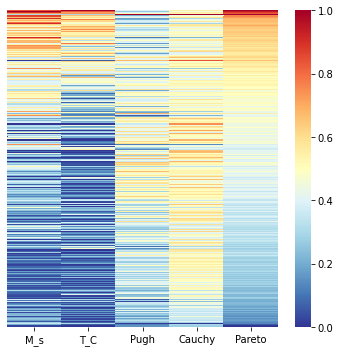

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('sorted_df.csv')
columns = ['M_s', 'T_C','Pugh', 'Cauchy']
min_values = {col: df[col].min() for col in columns}
df = df[~df.apply(lambda row: any(row[col] == min_values[col] for col in columns), axis=1)]

columns_to_normalize_old = ['M_s', 'T_C', 'Pugh', 'Cauchy']
columns_to_normalize = [f"{i}_new" for i in columns_to_normalize_old]
df[columns_to_normalize] = df[columns_to_normalize_old].copy().apply(
    lambda x: (x - x.min()) / (x.max() - x.min())
)
df['pareto'] = np.sqrt(df['M_s_new']**2 + df['T_C_new']**2 + df['Pugh_new']**2 + df['Cauchy_new']**2)
df['pareto_new'] = df[['pareto']].copy().apply(
    lambda x: (x - x.min()) / (x.max() - x.min())
)
data = df[['M_s_new', 'T_C_new', 'Pugh_new', 'Cauchy_new', 'pareto_new']]
print(data.describe())

# columns = ['Pugh_new', 'Cauchy_new']
# min_values = {col: data[col].min() for col in columns}
# data = data[~data.apply(lambda row: any(row[col] == min_values[col] for col in columns), axis=1)]
# print(data.describe())

fig, ax = plt.subplots(figsize = (5,5))
sns.heatmap(data,               # 鸢尾花数据数组
            cmap = 'RdYlBu_r', # 指定色谱
            ax = ax,           # 指定轴
            vmax = 1,          # 色谱最大值
            vmin = 0,          # 色谱最小值
            xticklabels = ['M_s', 'T_C', 'Pugh', 'Cauchy', 'Pareto'],  # 不显示横轴标签
            yticklabels = [],  # 不显示纵轴标签
            cbar = True)       # 显示色谱条
plt.tight_layout()
plt.show()
# ## fig.savefig('Figures/鸢尾花数据热图.svg', format='svg')